# 5.3 전이 학습
이미지넷처럼 아주 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 우리가 해결하려는 과제에 맞게 보정해서 사용하는 것을 의미한다.

이때 아주 큰 데이터셋을 사용하여 훈련된 모델은 사전 훈련된 모델(네트워크)이라고 한다.

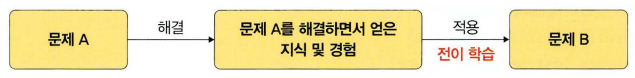

## 5.3.1 특성 추출 기법

특성 추출은 ImageNet 데이터셋으로 사전 훈련된 모델을 가져온 후 마지막에 완전연결층 부분만 새로 만든다. 즉, 학습할 때는 마지막 완전연결층만 학습하고 나머지 계층들은 학습되지 않도록 한다.

특성 추출은 이미지 분류를 위해 두 부분으로 구성된다.
1. 합성곱층: 합성곱층과 풀링층으로 구성
2. 데이터 분류기(완전연결층): 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분

사용 가능한 이미지 분류 모델
- Xception
- Inception V3
- ResNet50
- VGG16
- VGG19
- MobileNet

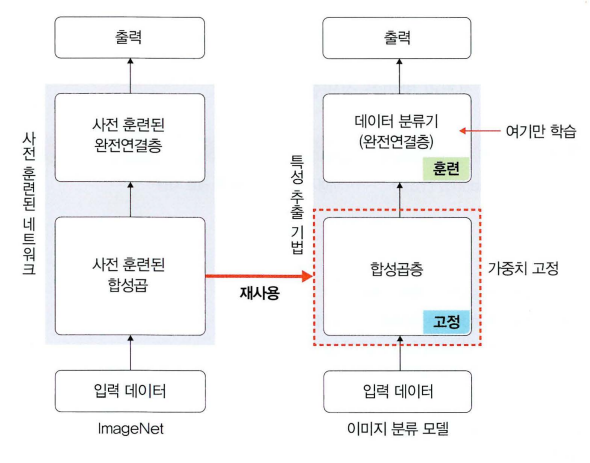

In [ ]:
import os
import time
import copy
import glob
import cv2
import shutil

import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [ ]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 23.81 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [ ]:
data_path = './080289/chap05/data/catanddog/train/'

transform = transforms.Compose(
    [
        transforms.Resize([256,256]),
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor()
    ]
)
train_dataset = torchvision.datasets.ImageFolder(data_path, transform=transform)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=32,
    num_workers=8,
    shuffle=True
)
print(len(train_dataset))

385


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


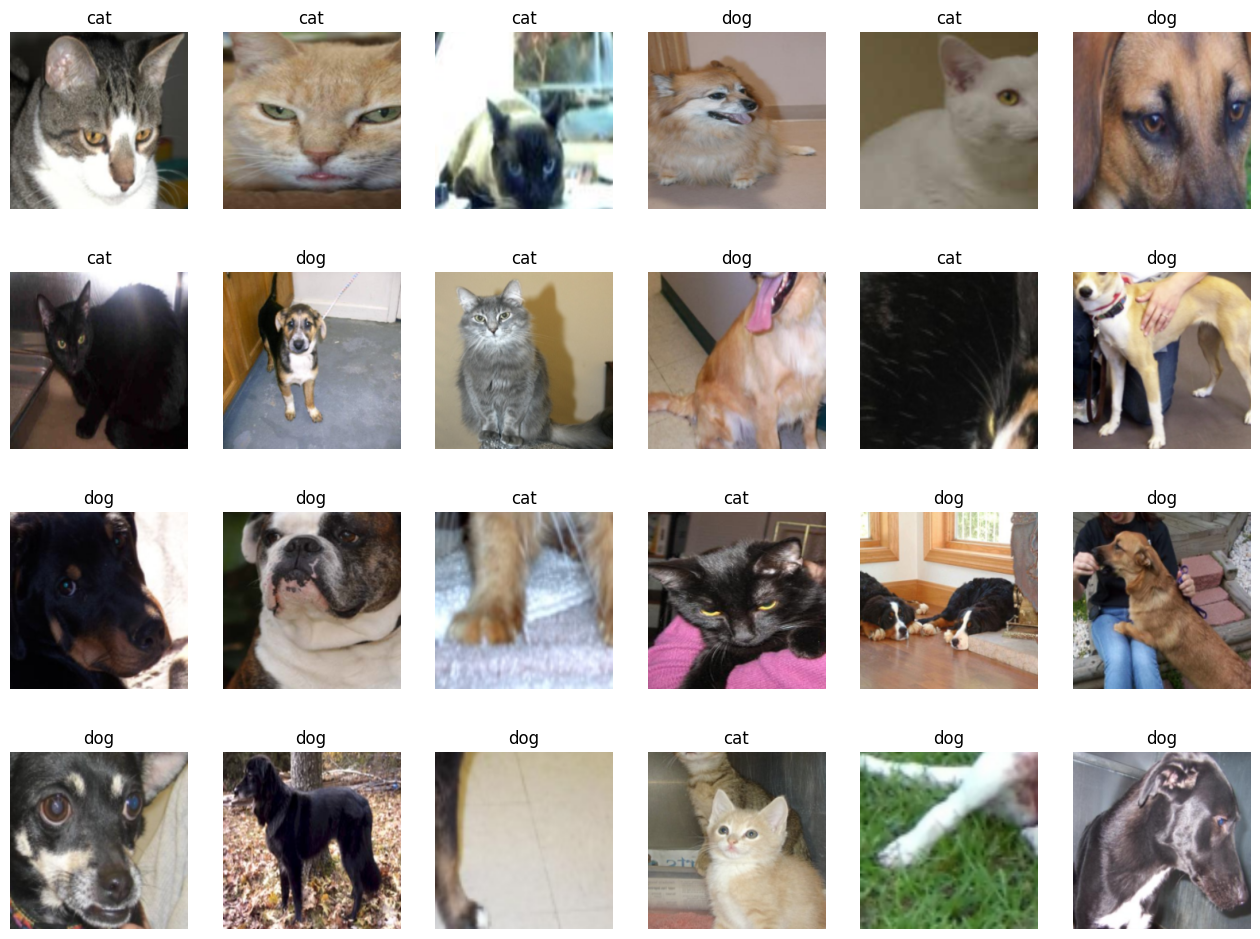

In [ ]:
import numpy as np

samples, labels = next(iter(train_loader))
classes = {0:'cat', 1:'dog'}
fig = plt.figure(figsize=(16,24))
for i in range(24):
  a = fig.add_subplot(4,6,i+1)
  a.set_title(classes[labels[i].item()])
  a.axis('off')
  a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

반복자를 사용하려면 iter()와 next()가 필요하다.
iter()는 전달된 데이터의 반복자를 꺼내 반환하며, next()는 그 반복자가 다음에 출력해야 할 요소를 반환한다.


In [ ]:
resnet18 = models.resnet18(pretrained=True)
# 사전 학습된 가중치를 사용하겠다는 의미

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 87.6MB/s]


ResNet18은 50개의 계층으로 구성된 합성곱 신경망이다.
ImageNet 데이터베이스의 100만개가 넘은 영상을 이용하여 훈련된 신경망으로 전이 학습에 사용되도록 사전 훈련된 모델을 제공하고 있다. 하지만 ResNet18은 입력 제약이 매우 크고, 충분한 메모리가 없으면 학습 속도가 느릴 수 있다는 단점이 있다.


In [ ]:
def set_parameter_requires_grad(model, feature_extracting=True):
  if feature_extracting:
    for param in model.parameters():
      param.requires_grad = False

set_parameter_requires_grad(resnet18)

In [ ]:
resnet18.fc= nn.Linear(512,2)

In [ ]:
for name, param in resnet18.named_parameters():
  if param.requires_grad:
    print(name, param.data)

fc.weight tensor([[ 0.0300,  0.0081,  0.0375,  ...,  0.0170,  0.0145, -0.0087],
        [ 0.0331,  0.0224, -0.0242,  ..., -0.0179,  0.0315,  0.0347]])
fc.bias tensor([-0.0148, -0.0018])


In [ ]:
model = models.resnet18(pretrained=True)

for param in model.parameters():
  param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters():
  param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss()
print(model)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13, is_train=True):
    since = time.time()
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloaders.dataset)
        epoch_acc = running_corrects.double() / len(dataloaders.dataset)

        print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join('./080289/chap05/data/catanddog/', '{0:0=2d}.pth'.format(epoch)))
        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))
    return acc_history, loss_history

마지막으로 ResNet18에 추가된 완전연결층은 학습을 하도록 설정한다.

학습을 통해 얻어지는 파라미터를 옵티마이저에서 전달해서 최종적으로 모델 학습에 사용한다.

In [12]:
params_to_update = []
for name, param in resnet18.named_parameters():
  if param.requires_grad ==True:
    params_to_update.append(param)
    print("\t", name)

optimizer = optim.Adam(params_to_update)

	 fc.weight
	 fc.bias


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion, optimizer, device)

Epoch 0/12
----------


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Loss: 0.6088 Acc: 0.6805

Epoch 1/12
----------
Loss: 0.4290 Acc: 0.7818

Epoch 2/12
----------
Loss: 0.3273 Acc: 0.8727

Epoch 3/12
----------
Loss: 0.2652 Acc: 0.9143

Epoch 4/12
----------
Loss: 0.2433 Acc: 0.9117

Epoch 5/12
----------
Loss: 0.2672 Acc: 0.8857

Epoch 6/12
----------
Loss: 0.2357 Acc: 0.9065

Epoch 7/12
----------
Loss: 0.2177 Acc: 0.9091

Epoch 8/12
----------
Loss: 0.2159 Acc: 0.9039

Epoch 9/12
----------
Loss: 0.2087 Acc: 0.9325

Epoch 10/12
----------
Loss: 0.1930 Acc: 0.9273

Epoch 11/12
----------
Loss: 0.2023 Acc: 0.9221

Epoch 12/12
----------
Loss: 0.2074 Acc: 0.9065

Training complete in 10m 26s
Best Acc: 0.932468


In [14]:
test_path = './080289/chap05/data/catanddog/test/'

transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
    ])
test_dataset = torchvision.datasets.ImageFolder(
    root=test_path,
    transform=transform
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    num_workers=1,
    shuffle=True
)
print(len(test_dataset))

98


In [15]:
def eval_model(model, dataloaders, device):
  since = time.time()
  acc_history = []
  best_acc = 0.0

  saved_models = glob.glob('./080289/chap05/data/catanddog/' + '*.pth')
  saved_models.sort()
  print('saved_model', saved_models)

  for model_path in saved_models:
    print('Loading model', model_path)

    model.load_state_dict(torch.load(model_path))
    model.eval()
    model.to(device)
    running_corrects = 0

    for inputs, labels in dataloaders:
      inputs = inputs.to(device)
      labels = labels.to(device)

      with torch.no_grad():
        outputs = model(inputs)

      _, preds = torch.max(outputs.data, 1)
      preds[preds >= 0.5] = 1
      preds[preds < 0.5] = 0
      running_corrects += preds.eq(labels).int().sum()

    epoch_acc = running_corrects.double() / len(dataloaders.dataset)
    print('Acc: {:.4f}'.format(epoch_acc))

    if epoch_acc > best_acc:
      best_acc = epoch_acc

    acc_history.append(epoch_acc.item())
    print()

  time_elapsed = time.time() - since
  print('Validation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
  print('Best Acc: {:4f}'.format(best_acc))

  return acc_history

In [16]:
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['./080289/chap05/data/catanddog/00.pth', './080289/chap05/data/catanddog/01.pth', './080289/chap05/data/catanddog/02.pth', './080289/chap05/data/catanddog/03.pth', './080289/chap05/data/catanddog/04.pth', './080289/chap05/data/catanddog/05.pth', './080289/chap05/data/catanddog/06.pth', './080289/chap05/data/catanddog/07.pth', './080289/chap05/data/catanddog/08.pth', './080289/chap05/data/catanddog/09.pth', './080289/chap05/data/catanddog/10.pth', './080289/chap05/data/catanddog/11.pth', './080289/chap05/data/catanddog/12.pth']
Loading model ./080289/chap05/data/catanddog/00.pth
Acc: 0.8469

Loading model ./080289/chap05/data/catanddog/01.pth
Acc: 0.9286

Loading model ./080289/chap05/data/catanddog/02.pth
Acc: 0.9388

Loading model ./080289/chap05/data/catanddog/03.pth
Acc: 0.9592

Loading model ./080289/chap05/data/catanddog/04.pth
Acc: 0.9184

Loading model ./080289/chap05/data/catanddog/05.pth
Acc: 0.9592

Loading model ./080289/chap05/data/catanddog/06.pth
Acc: 0.9490


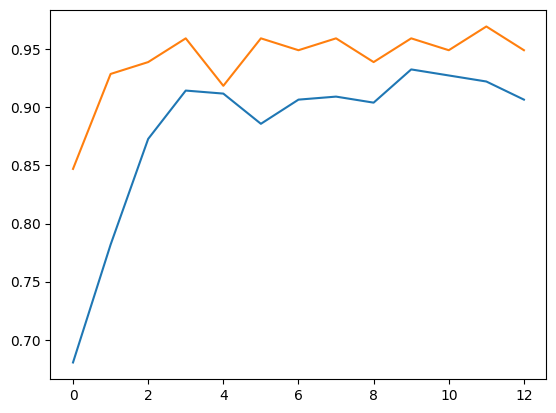

In [17]:
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

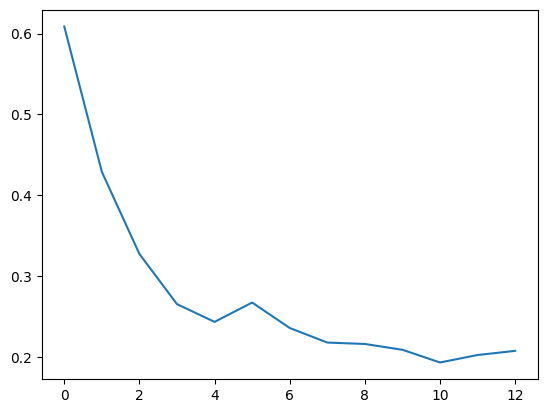

In [18]:
plt.plot(train_loss_hist)
plt.show()

In [19]:
def im_convert(tensor):
  image = tensor.clone().detach().numpy()
  image = image.transpose(1,2,0)
  image = image * (np.array((0.5,0.5,0.5))+np.array((0.5,0.5,0.5)))
  image = image.clip(0,1)
  return image

-  detach()는 기존 텐서에서 기울기가 전파되지 않는 텐서이다. 즉, tensor.clone().detach()는 기존 텐서를 복사한 새로운 텐서를 생성하지만 기울기에 영향을 주지 않겠다는 의미

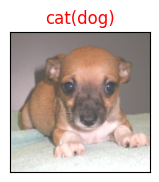

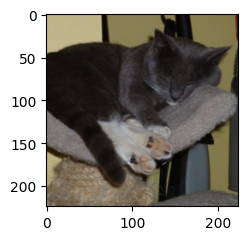

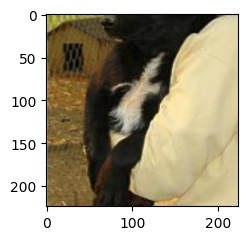

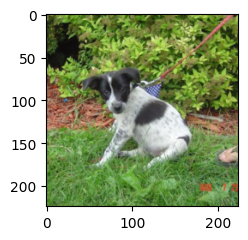

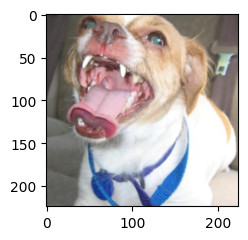

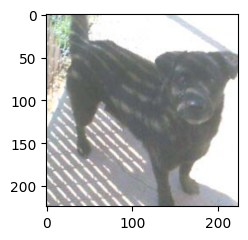

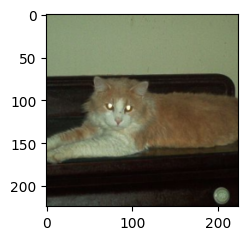

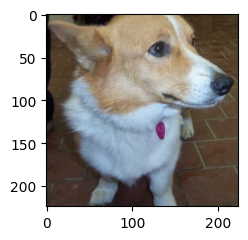

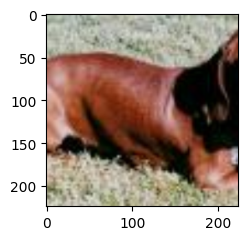

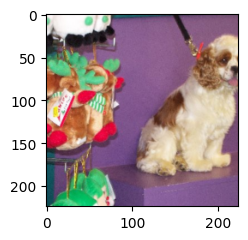

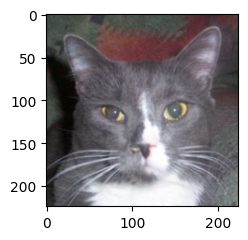

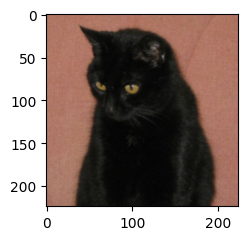

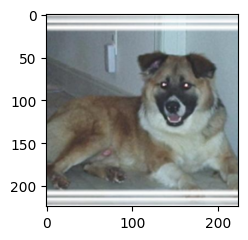

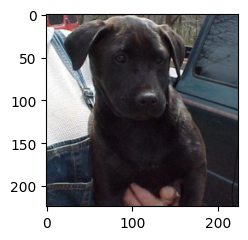

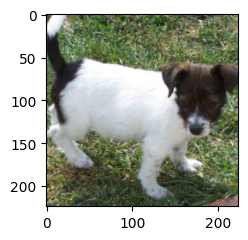

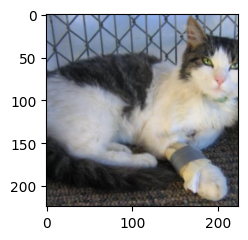

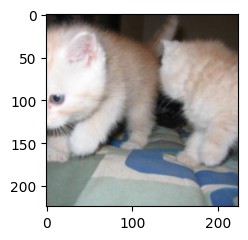

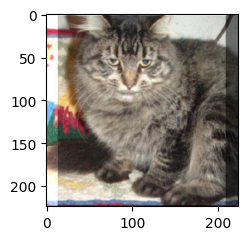

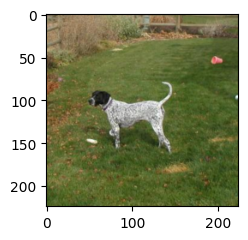

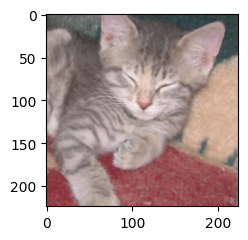

<Figure size 640x480 with 0 Axes>

In [22]:
classes = {0:'cat', 1:'dog'}

dataiter = iter(test_loader)
images, labels = next(dataiter)
output = model(images)
_, preds = torch.max(output,1)

fig = plt.figure(figsize=(25,4))
for idx in np.arange(20):
  ax = fig.add_subplot(2,10, idx+1, xticks=[], yticks=[])
  plt.imshow(im_convert(images[idx]))
  ax.set_title("{}({})".format(str(classes[preds[idx].item()]),
                               str(classes[labels[idx].item()])),
                color=("green" if preds[idx]==labels[idx] else "red"))
  plt.show()
  plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

add_subplot(2, 10, idx+1 , xticks=[] , yticks=[])

- idx+1:  세 번째 파라미터 : 인텍스를 의미하는데 행과 열을 기준으로 순차적으로 이미지를 출력
- 2, 10: 첫번째파라미터:행의수를의미하는데 이미지를 두 줄로 출력, 두 번째 파라미터 : 열의 수를 의미하는데， 한 줄에 열 개의 이미지를 출력

## 5.3.2 미세 조정 기법

특성 추출 기법에서 더 나아가 사전 훈련된 모델과 합성곱층, 데이터 분류기의 가중치를 업데이트하여 훈련시키는 방식

특성 추출은 목표 특성을 잘 추출했다는 전제하에 좋은 성능을 낼 수 있다.

**미세 조정기법**은 새로운 이미지 데이터를 사용하여 네트워크의 가중치를 업데이트해서 특성을 다시 추출할 수 있다. 즉, 사전 학습된 모델을 목적에 맞게 재학습시키거나 학습된 가중치의 일부를 재학습시키는 것이다.



###전략

- 데이터셋이 크고 사전 훈련된 모델과 유사성이 작을 경우

: 모델 전체를 재학습

- 데이터셋이 크고 사전 훈련된 모델과 유사성이 클 경우

: 합성곱층의 뒷부분과 데이터 분류기를 학습시킴

- 데이터셋이 작고 사전 훈련된 모델과 유사성이 작을 경우

: 합성곱층의 일부분과 데이터 분류기를 학습시킴.

- 데이터셋이 작고 사전 훈련된 모델과 유사성이 클 경우

: 데이터 분류기만 학습시킴. 데이터가 적기 때문에 많은 계층에 미세 조정 기법을 적용하면 과적합이 발생할 수 있다.

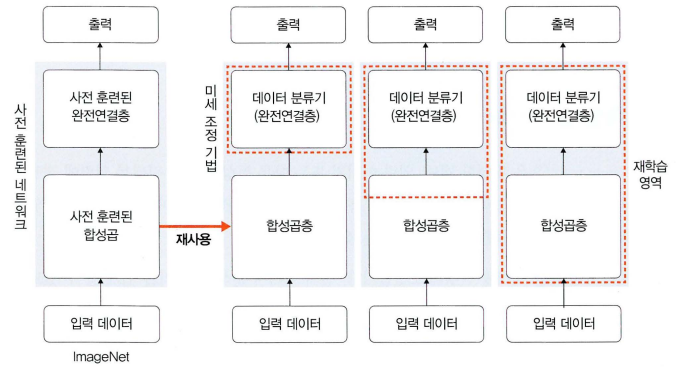